In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.tree import DecisionTreeClassifier

In [2]:
X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=6,
    weights=[0.8, 0.2],
    random_state=42
)

print("Distribusi kelas:", np.bincount(y))

Distribusi kelas: [797 203]


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Proporsi kelas train:")
print(np.bincount(y_train) / len(y_train))

print("Proporsi kelas test:")
print(np.bincount(y_test) / len(y_test))

Proporsi kelas train:
[0.7975 0.2025]
Proporsi kelas test:
[0.795 0.205]


In [4]:
model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

train_sizes, train_scores, val_scores = learning_curve(
    model,
    X_train,
    y_train,
    cv=5,
    train_sizes=np.linspace(0.1, 1.0, 8),
    scoring="accuracy"
)

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

In [5]:
print("Skor train pada ukuran data terbesar:",
      round(train_mean[-1], 3))

print("Skor validasi pada ukuran data terbesar:",
      round(val_mean[-1], 3))

print("Gap (indikasi overfitting jika besar):",
      round(train_mean[-1] - val_mean[-1], 3))

Skor train pada ukuran data terbesar: 0.929
Skor validasi pada ukuran data terbesar: 0.885
Gap (indikasi overfitting jika besar): 0.044


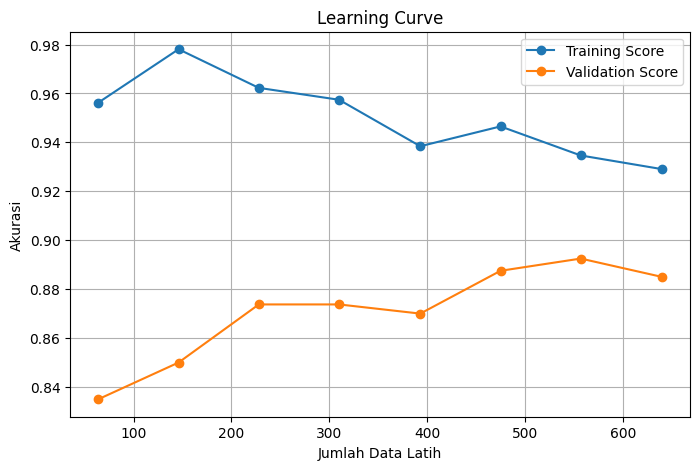

In [6]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_sizes, train_mean, "o-",
    label="Training Score"
)

plt.plot(
    train_sizes, val_mean, "o-",
    label="Validation Score"
)

plt.xlabel("Jumlah Data Latih")
plt.ylabel("Akurasi")
plt.title("Learning Curve")
plt.legend()
plt.grid(True)
plt.show()


max_depth = 1
Skor train: 0.806
Skor validasi: 0.789
Gap: 0.017


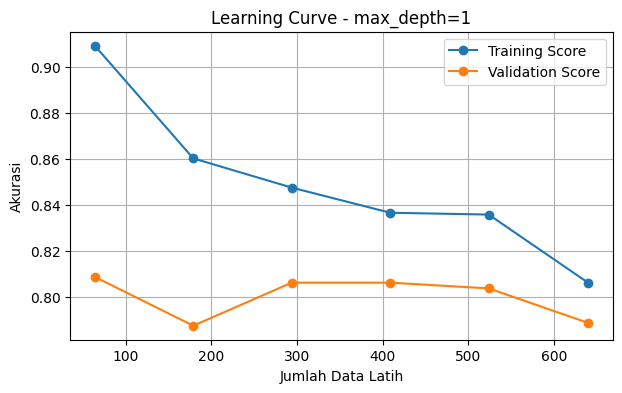


max_depth = 4
Skor train: 0.929
Skor validasi: 0.885
Gap: 0.044


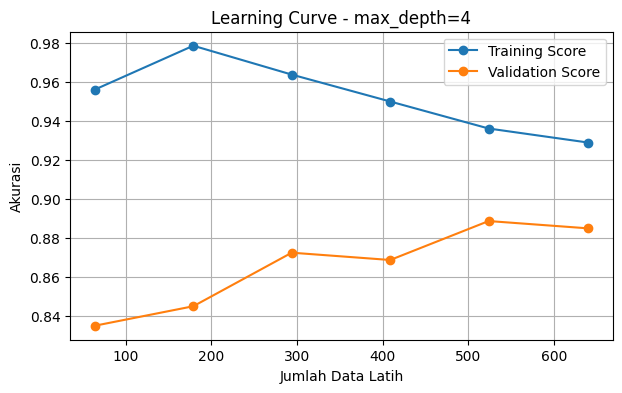


max_depth = None
Skor train: 1.000
Skor validasi: 0.878
Gap: 0.122


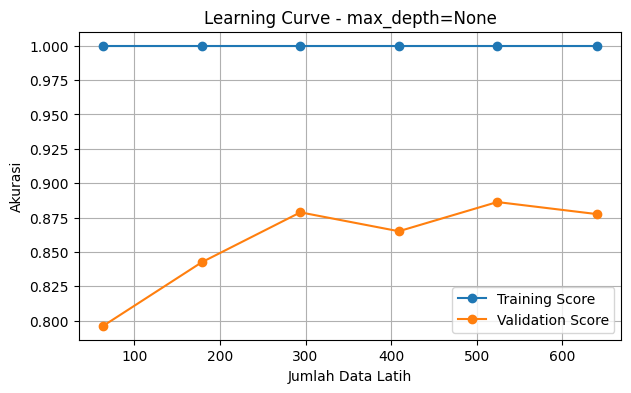

In [7]:
# Membandingkan learning curve untuk max_depth berbeda

for depth in [1, 4, None]:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    train_sizes, train_scores, val_scores = learning_curve(
        model,
        X_train,
        y_train,
        cv=5,
        train_sizes=np.linspace(0.1, 1.0, 6),
        scoring="accuracy"
    )

    train_mean = train_scores.mean(axis=1)
    val_mean = val_scores.mean(axis=1)

    print(f"\nmax_depth = {depth}")
    print(f"Skor train: {train_mean[-1]:.3f}")
    print(f"Skor validasi: {val_mean[-1]:.3f}")
    print(f"Gap: {train_mean[-1] - val_mean[-1]:.3f}")

    # Visualisasi learning curve
    plt.figure(figsize=(7, 4))

    plt.plot(
        train_sizes, train_mean, "o-",
        label="Training Score"
    )

    plt.plot(
        train_sizes, val_mean, "o-",
        label="Validation Score"
    )

    plt.xlabel("Jumlah Data Latih")
    plt.ylabel("Akurasi")
    plt.title(f"Learning Curve - max_depth={depth}")
    plt.legend()
    plt.grid(True)
    plt.show()

# Tuliskan diagnosis berdasarkan skor dan grafik
# untuk setiap nilai max_depth.